# LLM Training and Ensemble Scaling -- Demo Notebook

This notebook demonstrates:
1. Inspecting the training data
2. Loading a trained model and generating text
3. Visualizing the ensemble scaling results

## 1. Inspect the Training Data

The training data is FineWeb-Edu tokenized with the GPT-2 tokenizer and stored as binary shards. Each shard has a 256-int32 header followed by uint16 token IDs.

In [1]:
import numpy as np
import tiktoken

enc = tiktoken.get_encoding("gpt2")
EOT = enc._special_tokens["<|endoftext|>"]  # 50256

def read_bin(path):
    """Read a binary data shard and return token array."""
    with open(path, "rb") as f:
        header = np.frombuffer(f.read(256 * 4), dtype=np.int32)
        tokens = np.frombuffer(f.read(), dtype=np.uint16)
    print(f"Shard: {path}")
    print(f"  Tokens: {header[2]:,}")
    return tokens

tokens = read_bin("edu_fineweb_fixed/edufineweb_val_000000.bin")

# Split into documents (delimited by EOT token) and show first 3
docs = []
current = []
for t in tokens:
    if t == EOT:
        if current:
            docs.append(current)
            current = []
    else:
        current.append(t)
    if len(docs) >= 3:
        break

for i, doc in enumerate(docs):
    text = enc.decode(doc)
    print(f"\n{'=' * 80}")
    print(f"DOCUMENT {i + 1} ({len(doc)} tokens)")
    print("=" * 80)
    print(text[:500] + ("..." if len(text) > 500 else ""))

Shard: edu_fineweb_fixed/edufineweb_val_000000.bin
  Tokens: 4,000,000

DOCUMENT 1 (845 tokens)
The Independent Jane
For all the love, romance and scandal in Jane Austen’s books, what they are really about is freedom and independence. Independence of thought and the freedom to choose.
Elizabeth’s refusal of Mr. Collins offer of marriage showed an independence seldom seen in heroines of the day. Her refusal of Mr. Darcy while triggered by anger showed a level of independence that left him shocked and stunned.
The freedom she exhibited in finally accepting him in direct defiance of Lady Cath...

DOCUMENT 2 (1055 tokens)
Taking Play Seriously
By ROBIN MARANTZ HENIG
Published: February 17, 2008
On a drizzly Tuesday night in late January, 200 people came out to hear a psychiatrist talk rhapsodically about play -- not just the intense, joyous play of children, but play for all people, at all ages, at all times. (All species too; the lecture featured touching photos of a polar bear and a husk

## 2. Load a Trained Model and Generate Text

The model definition below mirrors `src/inference.py` -- it uses `scaled_dot_product_attention` instead of `flex_attention`, so it works on CPU, MPS, and CUDA without `torch.compile`.

In [2]:
import torch
from torch import nn
import torch.nn.functional as F
from dataclasses import dataclass

# ---------------------------------------------------------------------------
# Model definition (inference-compatible, no flex_attention or torch.compile)
# ---------------------------------------------------------------------------

class Rotary(nn.Module):
    def __init__(self, dim, base=10000):
        super().__init__()
        self.dim = dim
        self.base = base
        self.inv_freq = None
        self.seq_len_cached = None
        self.cos_cached = None
        self.sin_cached = None

    def forward(self, x, dtype):
        T = x.shape[1]
        if T != self.seq_len_cached:
            self.inv_freq = 1.0 / (self.base ** (torch.arange(0, self.dim, 2, device=x.device).float() / self.dim))
            self.seq_len_cached = T
            t = torch.arange(T, device=x.device).type_as(self.inv_freq)
            freqs = torch.outer(t, self.inv_freq)
            self.cos_cached = freqs.cos().to(dtype)
            self.sin_cached = freqs.sin().to(dtype)
        return self.cos_cached[None, :, None, :], self.sin_cached[None, :, None, :]


def apply_rotary_emb(x, cos, sin):
    d = x.shape[-1] // 2
    x1, x2 = x[..., :d], x[..., d:]
    y1 = x1 * cos + x2 * sin
    y2 = x1 * (-sin) + x2 * cos
    return torch.cat([y1, y2], dim=-1).type_as(x)


class CastedLinear(nn.Linear):
    def forward(self, x):
        return F.linear(x, self.weight.to(x.dtype))


class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n_head = cfg.n_head
        self.n_embd = cfg.n_embd
        self.head_dim = cfg.n_embd // cfg.n_head
        self.c_q = CastedLinear(cfg.n_embd, cfg.n_embd, bias=False)
        self.c_k = CastedLinear(cfg.n_embd, cfg.n_embd, bias=False)
        self.c_v = CastedLinear(cfg.n_embd, cfg.n_embd, bias=False)
        self.c_proj = CastedLinear(cfg.n_embd, cfg.n_embd, bias=False)
        self.rotary = Rotary(self.head_dim)
        self.lamb = nn.Parameter(torch.tensor(0.5))

    def forward(self, x, v1):
        B, T, C = x.shape
        q = self.c_q(x).view(B, T, self.n_head, self.head_dim)
        k = self.c_k(x).view(B, T, self.n_head, self.head_dim)
        v = self.c_v(x).view(B, T, self.n_head, self.head_dim)
        if v1 is None:
            v1 = v
        v = (1 - self.lamb) * v + self.lamb * v1.view_as(v)
        cos, sin = self.rotary(q, x.dtype)
        q = F.rms_norm(q, (q.size(-1),))
        k = F.rms_norm(k, (k.size(-1),))
        q = apply_rotary_emb(q, cos, sin)
        k = apply_rotary_emb(k, cos, sin)
        y = F.scaled_dot_product_attention(
            q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2), is_causal=True
        )
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y), v1


class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.c_fc = CastedLinear(cfg.n_embd, 4 * cfg.n_embd, bias=False)
        self.c_proj = CastedLinear(4 * cfg.n_embd, cfg.n_embd, bias=False)

    def forward(self, x):
        return self.c_proj(F.relu(self.c_fc(x)).square())


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.attn = CausalSelfAttention(cfg)
        self.mlp = MLP(cfg)
        self.lambdas = nn.Parameter(torch.tensor([1., 0.]))

    def forward(self, x, v1, x0):
        x = self.lambdas[0] * x + self.lambdas[1] * x0
        x1, v1 = self.attn(F.rms_norm(x, (x.size(-1),)), v1)
        x = x + x1
        x = x + self.mlp(F.rms_norm(x, (x.size(-1),)))
        return x, v1


@dataclass
class GPTConfig:
    vocab_size: int = 50304
    n_layer: int = 12
    n_head: int = 6
    n_embd: int = 768

Config = GPTConfig  # alias for checkpoint compatibility


class GPT(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.cfg = cfg
        self.num_encoder_layers = cfg.n_layer // 2
        self.num_decoder_layers = cfg.n_layer - self.num_encoder_layers
        self.skip_weights = nn.Parameter(torch.ones(self.num_decoder_layers))
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(cfg.vocab_size, cfg.n_embd),
            h=nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)]),
        ))
        self.lm_head = CastedLinear(cfg.n_embd, cfg.vocab_size, bias=False)

    def forward(self, idx):
        x = self.transformer.wte(idx)
        x = F.rms_norm(x, (x.size(-1),))
        x0, v1 = x, None
        skips = []
        for i in range(self.num_encoder_layers):
            x, v1 = self.transformer.h[i](x, v1, x0)
            skips.append(x)
        for i in range(self.num_decoder_layers):
            x = x + self.skip_weights[i] * skips.pop()
            x, v1 = self.transformer.h[self.num_encoder_layers + i](x, v1, x0)
        x = F.rms_norm(x, (x.size(-1),))
        logits = self.lm_head(x)
        logits = 30 * torch.tanh(logits / 30)
        return logits

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=50):
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= 1024 else idx[:, -1024:]
            logits = self.forward(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float('-inf')
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, idx_next], dim=1)
        return idx


def load_model(checkpoint_path, device="cpu", dtype=torch.float32):
    """Load a trained checkpoint into the inference-compatible model."""
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    cfg = GPTConfig()
    state_dict = checkpoint['model_state_dict']
    new_state_dict = {}
    for k, v in state_dict.items():
        if k.startswith('module.'):
            k = k[7:]
        if v.dtype == torch.bfloat16:
            v = v.to(dtype)
        new_state_dict[k] = v
    model = GPT(cfg)
    model.load_state_dict(new_state_dict)
    model = model.to(device).to(dtype)
    model.eval()
    num_params = sum(p.numel() for p in model.parameters())
    print(f"Loaded: {checkpoint_path}")
    print(f"  Parameters: {num_params:,}")
    print(f"  Step: {checkpoint.get('step', 'N/A')}")
    print(f"  Val loss: {checkpoint.get('val_loss', 'N/A')}")
    return model

print("Model definition ready.")

Model definition ready.


In [3]:
# Load one of the trained models
# Change the path to any checkpoint you have available
CHECKPOINT = "checkpoints/model_200m_1_best.pt"

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Device: {device}")

model = load_model(CHECKPOINT, device=device)

Device: mps
Loaded: checkpoints/model_200m_1_best.pt
  Parameters: 162,201,642
  Step: 1145
  Val loss: 3.4448940753936768


In [4]:
# Generate text from several prompts
prompts = [
    "The theory of evolution",
    "In mathematics, a prime number is",
    "The solar system consists of",
    "Machine learning algorithms can",
]

for prompt in prompts:
    tokens = enc.encode(prompt)
    x = torch.tensor([tokens], dtype=torch.long, device=device)
    output = model.generate(x, max_new_tokens=100, temperature=0.8, top_k=50)
    text = enc.decode(output[0].tolist())
    print(f"Prompt: {prompt}")
    print(f"{'─' * 70}")
    print(text)
    print(f"\n{'=' * 70}\n")

Prompt: The theory of evolution
──────────────────────────────────────────────────────────────────────
The theory of evolution is that the universe evolved out of a process of evolution, that is, the change of the structure of the universe, and that, in some cases, the universe itself evolved out of the same process. Evolution proceeds from a process of evolution.
All the processes of evolution are continuous processes. There are no fixed rules of evolution for the evolution of species. It is a process of evolution that is eternal and immutable. There is no fixed rules of evolution for a species. There is no fixed rules


Prompt: In mathematics, a prime number is
──────────────────────────────────────────────────────────────────────
In mathematics, a prime number is a number that is a constant. There is an element of the prime with the same mass at the base and the same unit at the top. Therefore, the prime number is a prime number. The prime number is an integer that is a prime number

## 2b. Ensemble Generation (4 Models)

Instead of sampling from a single model's logits, we load all four 200M-budget checkpoints and **average their logits** at every generation step before sampling. Because the four models converge to very different regions of weight space (despite identical training data order), their prediction errors are largely uncorrelated — averaging cancels noise and sharpens the distribution over the correct next token.

In [5]:
# Load all 4 models trained on 200M tokens
CHECKPOINTS_200M = [
    "checkpoints/model_200m_1_best.pt",
    "checkpoints/model_200m_2_best.pt",
    "checkpoints/model_200m_3_best.pt",
    "checkpoints/model_200m_4_best.pt",
]

ensemble_models = []
for ckpt in CHECKPOINTS_200M:
    m = load_model(ckpt, device=device)
    ensemble_models.append(m)

print(f"\nLoaded {len(ensemble_models)} models for ensemble generation.")


@torch.no_grad()
def ensemble_generate(models, idx, max_new_tokens, temperature=0.8, top_k=50):
    """Generate tokens by averaging logits across all models at each step."""
    for _ in range(max_new_tokens):
        idx_cond = idx if idx.size(1) <= 1024 else idx[:, -1024:]

        # Average logits from all models
        avg_logits = None
        for m in models:
            logits = m(idx_cond)[:, -1, :]   # (B, vocab)
            avg_logits = logits if avg_logits is None else avg_logits + logits
        avg_logits = avg_logits / len(models)

        avg_logits = avg_logits / temperature
        if top_k is not None:
            v, _ = torch.topk(avg_logits, min(top_k, avg_logits.size(-1)))
            avg_logits[avg_logits < v[:, [-1]]] = float('-inf')

        probs = F.softmax(avg_logits, dim=-1)
        idx_next = torch.multinomial(probs, num_samples=1)
        idx = torch.cat([idx, idx_next], dim=1)
    return idx


# Compare single-model vs 4-model ensemble on the same prompts
prompts = [
    "The theory of evolution",
    "In mathematics, a prime number is",
    "The solar system consists of",
    "Machine learning algorithms can",
]

for prompt in prompts:
    tokens = enc.encode(prompt)
    x = torch.tensor([tokens], dtype=torch.long, device=device)

    single_out = model.generate(x, max_new_tokens=100, temperature=0.8, top_k=50)
    ensemble_out = ensemble_generate(ensemble_models, x, max_new_tokens=100, temperature=0.8, top_k=50)

    print(f"Prompt: {prompt}")
    print(f"{'─' * 70}")
    print(f"[Single model]\n{enc.decode(single_out[0].tolist())}")
    print(f"\n[4-model ensemble]\n{enc.decode(ensemble_out[0].tolist())}")
    print(f"\n{'=' * 70}\n")

Loaded: checkpoints/model_200m_1_best.pt
  Parameters: 162,201,642
  Step: 1145
  Val loss: 3.4448940753936768
Loaded: checkpoints/model_200m_2_best.pt
  Parameters: 162,201,642
  Step: 1145
  Val loss: 3.4463071823120117
Loaded: checkpoints/model_200m_3_best.pt
  Parameters: 162,201,642
  Step: 1145
  Val loss: 3.4453279972076416
Loaded: checkpoints/model_200m_4_best.pt
  Parameters: 162,201,642
  Step: 1145
  Val loss: 3.444852113723755

Loaded 4 models for ensemble generation.
Prompt: The theory of evolution
──────────────────────────────────────────────────────────────────────
[Single model]
The theory of evolution was accepted by the scientific and theological world by the early scientific community.
‘The theory of evolution is a fallacy or fallacy.’
‘It is not because the theory is incomplete, the theory is incomplete because it lacks validity.’
‘It is not because there are no “missing” points in the theory.‚
‘The theory of evolution must be valid and reliable because it is not t

## 3. Ensemble Scaling Results

Load and visualize the ensemble scaling analysis. For each token budget (50M, 100M, 200M), four independently trained models are combined in all possible subsets (1, 2, 3, 4 models) and evaluated via logit averaging.

In [6]:
import json
import matplotlib.pyplot as plt

with open("results/ensemble_scaling_results.json") as f:
    results = json.load(f)

budgets = ["50m", "100m", "200m"]
budget_labels = {"50m": "50M tokens", "100m": "100M tokens", "200m": "200M tokens"}
colors = {"50m": "#2196F3", "100m": "#FF9800", "200m": "#4CAF50"}
x_vals = [1, 2, 3, 4]

# --- Print summary table ---
print("Test Set Perplexity")
print(f"{'Ensemble':>10}  {'50M':>18}  {'100M':>18}  {'200M':>18}")
print("-" * 70)
for k in x_vals:
    row = f"{k} model(s):  "
    for budget in budgets:
        data = results[budget]["test"][str(k)]
        mean = data["mean_ppl"]
        std = data["std_ppl"]
        if std > 0:
            row += f"{mean:>8.2f} +/- {std:<5.2f}  "
        else:
            row += f"{mean:>8.2f}          "
    print(row)

# --- Improvement summary ---
print(f"\nPerplexity reduction (1 model -> 4 models, test set):")
for budget in budgets:
    single = results[budget]["test"]["1"]["mean_ppl"]
    ensemble = results[budget]["test"]["4"]["mean_ppl"]
    reduction = (single - ensemble) / single * 100
    print(f"  {budget_labels[budget]}: {single:.2f} -> {ensemble:.2f} ({reduction:.1f}% reduction)")

Test Set Perplexity
  Ensemble                 50M                100M                200M
----------------------------------------------------------------------
1 model(s):     47.35 +/- 0.21      35.24 +/- 0.18      28.72 +/- 0.07   
2 model(s):     43.75 +/- 0.16      32.44 +/- 0.07      26.28 +/- 0.05   
3 model(s):     42.63 +/- 0.09      31.57 +/- 0.04      25.53 +/- 0.03   
4 model(s):     42.09             31.15             25.16          

Perplexity reduction (1 model -> 4 models, test set):
  50M tokens: 47.35 -> 42.09 (11.1% reduction)
  100M tokens: 35.24 -> 31.15 (11.6% reduction)
  200M tokens: 28.72 -> 25.16 (12.4% reduction)


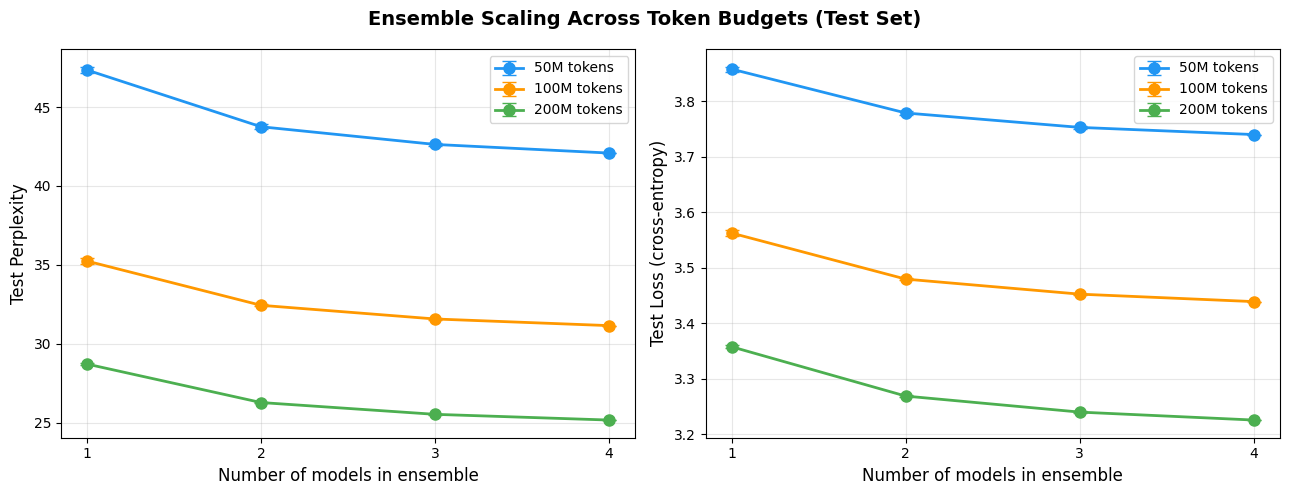

In [7]:
# --- Plot: Test perplexity vs ensemble size (all budgets overlaid) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for budget in budgets:
    test_data = results[budget]["test"]
    val_data = results[budget]["val"]

    # Test perplexity
    means = [test_data[str(k)]["mean_ppl"] for k in x_vals]
    stds = [test_data[str(k)]["std_ppl"] for k in x_vals]
    ax1.errorbar(x_vals, means, yerr=stds, marker='o', color=colors[budget],
                 capsize=5, linewidth=2, markersize=8, label=budget_labels[budget])

    # Test loss
    means_loss = [test_data[str(k)]["mean_loss"] for k in x_vals]
    stds_loss = [test_data[str(k)]["std_loss"] for k in x_vals]
    ax2.errorbar(x_vals, means_loss, yerr=stds_loss, marker='o', color=colors[budget],
                 capsize=5, linewidth=2, markersize=8, label=budget_labels[budget])

ax1.set_xlabel("Number of models in ensemble", fontsize=12)
ax1.set_ylabel("Test Perplexity", fontsize=12)
ax1.set_xticks(x_vals)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

ax2.set_xlabel("Number of models in ensemble", fontsize=12)
ax2.set_ylabel("Test Loss (cross-entropy)", fontsize=12)
ax2.set_xticks(x_vals)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

fig.suptitle("Ensemble Scaling Across Token Budgets (Test Set)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

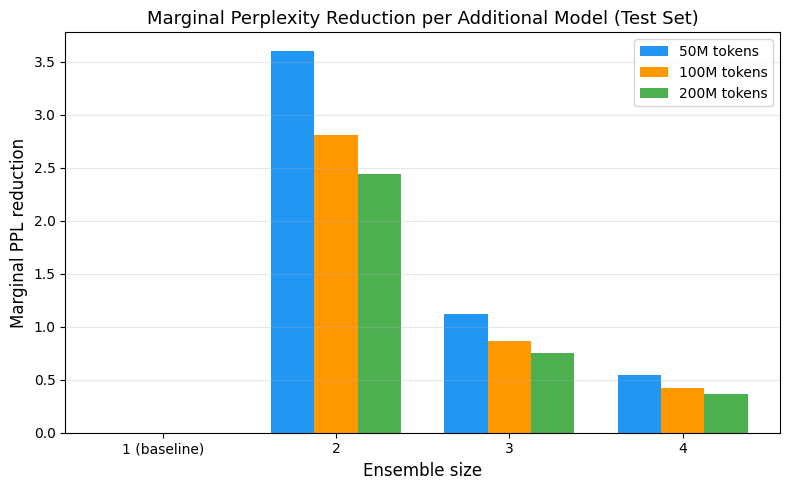

In [8]:
# --- Plot: Marginal gain from each additional model ---
fig, ax = plt.subplots(figsize=(8, 5))

for budget in budgets:
    test_data = results[budget]["test"]
    means = [test_data[str(k)]["mean_ppl"] for k in x_vals]
    # Marginal improvement: how much PPL drops when adding the k-th model
    marginal = [0] + [means[i-1] - means[i] for i in range(1, len(means))]
    ax.bar([x + (budgets.index(budget) - 1) * 0.25 for x in x_vals],
           marginal, width=0.25, color=colors[budget], label=budget_labels[budget])

ax.set_xlabel("Ensemble size", fontsize=12)
ax.set_ylabel("Marginal PPL reduction", fontsize=12)
ax.set_xticks(x_vals)
ax.set_xticklabels(["1 (baseline)", "2", "3", "4"])
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.set_title("Marginal Perplexity Reduction per Additional Model (Test Set)", fontsize=13)
plt.tight_layout()
plt.show()

## 4. Compute Perplexity on Validation Data

Quick demonstration of computing perplexity with a single model on a subset of the validation set.

In [9]:
@torch.no_grad()
def compute_perplexity(model, tokens, device, batch_size=8, seq_len=1024, max_batches=50):
    """Compute perplexity on a token array."""
    tokens_t = torch.tensor(tokens, dtype=torch.long)
    n_windows = len(tokens_t) // (seq_len + 1)

    total_loss = 0.0
    total_tokens = 0

    for i in range(0, min(n_windows, max_batches * batch_size), batch_size):
        batch_end = min(i + batch_size, n_windows)
        x_list, y_list = [], []
        for j in range(i, batch_end):
            start = j * (seq_len + 1)
            window = tokens_t[start:start + seq_len + 1]
            x_list.append(window[:-1])
            y_list.append(window[1:])

        x = torch.stack(x_list).to(device)
        y = torch.stack(y_list).to(device)

        logits = model(x)
        loss = F.cross_entropy(
            logits.float().view(-1, logits.size(-1)), y.view(-1), reduction='sum'
        )
        total_loss += loss.item()
        total_tokens += y.numel()

    avg_loss = total_loss / total_tokens
    ppl = np.exp(avg_loss)
    return avg_loss, ppl

# Load validation tokens
val_tokens = read_bin("edu_fineweb_fixed/edufineweb_val_000000.bin")

# Compute perplexity (first 50 batches for speed)
loss, ppl = compute_perplexity(model, val_tokens, device, batch_size=8, max_batches=50)
print(f"\nValidation (first 50 batches):")
print(f"  Loss: {loss:.4f}")
print(f"  Perplexity: {ppl:.2f}")

Shard: edu_fineweb_fixed/edufineweb_val_000000.bin
  Tokens: 4,000,000

Validation (first 50 batches):
  Loss: 3.4160
  Perplexity: 30.45
